# Wall Segmentation + Normal Vector Analysis

This notebook helps visualize and analyze RGB->X model outputs (normal vectors) and will later integrate with SegFormer for wall segmentation.

## 1. Setup & Configuration
Configure all paths here - update these with your actual paths

In [1]:
# Path configurations - UPDATE THESE
INPUT_IMAGES_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images"  # Directory with original RGB images
RGBX_OUTPUTS_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"  # Directory with .npy files from RGB->X model
EXTERNAL_MODULE_PATH = "/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules"  # Path to directory containing SegFormer module
OUTPUT_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"  # Where to save visualizations and results

# File extension for RGB->X outputs
NORMAL_NPY_SUFFIX = "normal.npy"  # Adjust based on your naming convention

print(f"Input images: {INPUT_IMAGES_DIR}")
print(f"RGB->X outputs: {RGBX_OUTPUTS_DIR}")
print(f"External module: {EXTERNAL_MODULE_PATH}")
print(f"Output directory: {OUTPUT_DIR}")

Input images: /Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images
RGB->X outputs: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output
External module: /Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules
Output directory: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output


## 2. Import Dependencies

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from pathlib import Path
import sys

# Add external module to path (for future SegFormer import)
if EXTERNAL_MODULE_PATH not in sys.path:
    sys.path.insert(0, EXTERNAL_MODULE_PATH)
    print(f"Added {EXTERNAL_MODULE_PATH} to Python path")

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("All dependencies imported successfully!")

Added /Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules to Python path
All dependencies imported successfully!


## 3. Visualising Wall Normals
Overlay Normal planes on top of the image for visualisation of accuracy

In [3]:
def create_wall_normal_overlay(input_image_path, normal_npy_path, wall_confidence_npy_path, 
                               confidence_threshold=0.5, blend_alpha=0.6):
    """
    Create an overlay visualization of wall normals on the original image.
    
    This function:
    1. Loads the original image, normal map, and wall confidence map
    2. Creates a binary mask from the confidence map using the threshold
    3. Extracts normals only for wall pixels
    4. Converts wall normals to RGB visualization
    5. Overlays the RGB wall normals on the original image
    
    Args:
        input_image_path: Path to original RGB image
        normal_npy_path: Path to normal.npy file (H×W×3 array, range [0,1])
        wall_confidence_npy_path: Path to wall_confidence.npy (H×W array, range [0,1])
        confidence_threshold: Threshold for wall classification (default: 0.5)
        blend_alpha: Alpha value for blending overlay (0=original, 1=full overlay, default: 0.6)
    
    Returns:
        dict containing:
            - 'overlay': PIL Image of the final composite
            - 'wall_normals_rgb': PIL Image of masked wall normals (RGB)
            - 'wall_mask': numpy array of binary wall mask (H×W, bool)
            - 'input_image': PIL Image of original input
    """
    # Load input image
    input_img = Image.open(input_image_path).convert('RGB')
    input_array = np.array(input_img)
    
    # Load normal map
    normals = np.load(normal_npy_path)
    
    # Load wall confidence map
    wall_confidence = np.load(wall_confidence_npy_path)
    
    # Create binary wall mask
    wall_mask = wall_confidence > confidence_threshold
    
    # Convert normals to RGB (using existing function)
    normals_rgb_array = (np.clip(normals, 0, 1) * 255).astype(np.uint8)
    
    # Create masked wall normals (set non-wall pixels to black)
    masked_wall_normals = normals_rgb_array.copy()
    masked_wall_normals[~wall_mask] = 0  # Set non-wall pixels to black
    
    # Convert to PIL Images
    wall_normals_rgb = Image.fromarray(masked_wall_normals)
    
    # Create overlay using alpha blending
    # Method: composite = (1-alpha) * original + alpha * wall_normals
    overlay = Image.blend(input_img, wall_normals_rgb, alpha=blend_alpha)
    
    return {
        'overlay': overlay,
        'wall_normals_rgb': wall_normals_rgb,
        'wall_mask': wall_mask,
        'input_image': input_img
    }

print("Wall normal overlay function created!")
print("Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)")

Wall normal overlay function created!
Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)


#### Core Function: Create Wall Normal Overlay
This function loads the three data sources (input image, normals, wall confidence), creates a binary mask from the confidence map, extracts wall normals, and blends them onto the original image. Normal vectors (x, y, z) can be visualized as RGB colors

In [4]:
def normalize_for_visualization(normals):
    """
    Convert normal vectors to RGB visualization.
    
    IMPORTANT: The model's pipeline already denormalizes the output from [-1, 1] to [0, 1]
    and does NOT apply gamma correction to normal maps. Therefore, the .npy files
    are already in the correct [0, 1] range for visualization.
    
    See: rgbx/rgb2x/pipeline_rgb2x.py lines 800-815
    - do_denormalize = True (converts [-1,1] to [0,1])
    - do_gamma_correction = False for normal maps
    """
    # Model outputs are already in [0, 1] - just clip to ensure valid range
    vis = np.clip(normals, 0, 1)
    return vis

def normals_to_rgb(normals):
    """
    Convert normal vectors to RGB image for visualization.
    Returns PIL Image.
    
    This matches the model's PNG preview generation:
    img_png = (np.clip(img_np, 0, 1) * 255).astype(np.uint8)
    """
    vis = normalize_for_visualization(normals)
    rgb_array = (vis * 255).astype(np.uint8)
    return Image.fromarray(rgb_array)

print("Visualization functions defined!")
print("NOTE: Updated to match model's output format (already in [0, 1] range)")

Visualization functions defined!
NOTE: Updated to match model's output format (already in [0, 1] range)


## 4. Wall Normal Extraction and Overlay Visualization

This section creates visualizations that combine SegFormer wall segmentation with RGB->X normal maps.

**What we're doing:**
1. Use SegFormer confidence maps to identify wall pixels
2. Extract normal vectors only for wall regions
3. Visualize wall normals as RGB colors
4. Overlay this RGB visualization on top of the original input image

This creates a composite image showing the normal vector directions of walls, making it easy to understand wall orientations in the scene.

### Test Visualization on Single Image
Test the overlay function on one image and display a 2×2 comparison grid showing: original image, wall mask, masked normals, and final overlay.

#### Helper Script: (Temporary) Renames files to ensure the have the input image file's name in their name

Renames all output files inside an image's directory to ensure it is prefixed by the image file's name.

In [5]:
# # Helper function to rename files in output directories
# with os.scandir(RGBX_OUTPUTS_DIR) as entries:
#     for entry in entries:
#         if entry.is_dir():
#             print(entry.name)
#             with os.scandir(entry.path) as files: 
#                 for file in files:
#                     # Find relevant files
#                     if file.name.startswith(entry.name):
#                         continue
#                     else:
#                         print(file.path)
#                         os.rename(file.path, os.path.join(entry.path, entry.name + "_" + file.name))

#### Helper Script: Creates a dict of all paths of an image for easy access

A dict specifies the naming convention of various output files and glob.glob finds those files without any specific extension being fixed.

In [6]:
import glob

# Test the overlay function on a single image
# Find first entry with complete data (input + normal + segmentation)
test_item = None
img_name = "bed_back_bedroom"
img_suffix = {
    "input": "",
    "irr_npy": "_irradiance",
    "irr_exr": "_irradiance_linear",
    "irr_img": "_irradiance_preview",
    "nor_npy": "_normal",
    "nor_img": "_normal_preview",
    "wall_npy": "_wall_confidence",
    "wall_img": "_wall_confidence_viz",
}

def create_dict(image_name):
    def search_file(pattern, dir):
        matches = glob.glob(os.path.join(dir, pattern))
        if matches: 
            return Path(matches[0])
    
    item = {}
    directory = f"{RGBX_OUTPUTS_DIR}/{image_name}"
    print(directory)

    for suffix in img_suffix.keys():
        item[suffix] = search_file(f"{image_name}{img_suffix[suffix]}.*", directory)
    print(item)
    return item

item = create_dict(img_name)


/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom
{'input': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom.jpg'), 'irr_npy': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_irradiance.npy'), 'irr_exr': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_irradiance_linear.exr'), 'irr_img': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_irradiance_preview.png'), 'nor_npy': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_normal.npy'), 'nor_img': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_normal_preview.png'), 'wall_npy': PosixPath('/Users/is

#### Test Run 

Testing on: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom.jpg



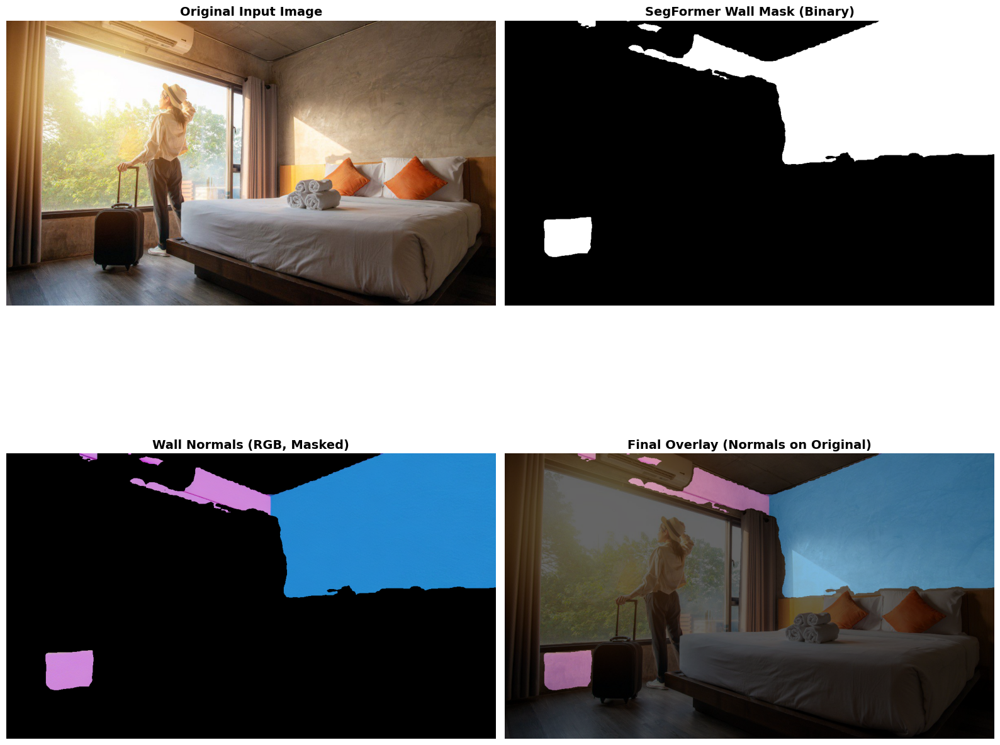

In [7]:
test_item = item

if test_item:
    print(f"Testing on: {test_item['input']}\n")
    
    # Create the overlay visualization
    result = create_wall_normal_overlay(
        input_image_path=test_item['input'],
        normal_npy_path=test_item['nor_npy'],
        wall_confidence_npy_path=test_item['wall_npy'],
        confidence_threshold=0.9,
        blend_alpha=0.6
    )
    
    # Display results in a 2×2 grid
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Top-left: Original input image
    axes[0, 0].imshow(result['input_image'])
    axes[0, 0].set_title('Original Input Image', fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Top-right: Wall mask visualization
    axes[0, 1].imshow(result['wall_mask'], cmap='gray')
    axes[0, 1].set_title('SegFormer Wall Mask (Binary)', fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Bottom-left: Masked wall normals (RGB)
    axes[1, 0].imshow(result['wall_normals_rgb'])
    axes[1, 0].set_title('Wall Normals (RGB, Masked)', fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    
    # Bottom-right: Final overlay composite
    axes[1, 1].imshow(result['overlay'])
    axes[1, 1].set_title('Final Overlay (Normals on Original)', fontsize=14, fontweight='bold')
    axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
else:
    print("No complete dataset entry found (need input + normal + wall_confidence)")
    print("Make sure to run SegFormer processing first (cell 13) and update dataset (cell 14)")



## 5. Edge Detection Tests

In [8]:
%pip install opencv-python


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Canny Edge Detection Functions

#### Canny - With Greyscale

In [9]:
import cv2

def detect_edges_simple(image):
    """Simple Canny edge detection."""
    # Load image if it's a path
    if isinstance(image, (str, Path)):
        image = cv2.imread(str(image))
        if image is None:
            raise ValueError(f"Could not load image from path: {image}")
    
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    print("Inside func: ", type(edges), edges.shape)
    return edges
    plt.tight_layout()
    plt.show()

In [10]:
def detect_edges_no_greyscale(image):
    """Simple Canny edge detection."""
    # Load image if it's a path
    if isinstance(image, (str, Path)):
        image = cv2.imread(str(image))
        if image is None:
            raise ValueError(f"Could not load image from path: {image}")
    
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    print("Inside func: ", type(edges), edges.shape)
    return edges
    plt.tight_layout()
    plt.show()

### Testing on Sample Image

#### Canny on input with Greyscale

Inside func:  <class 'numpy.ndarray'> (700, 1200)


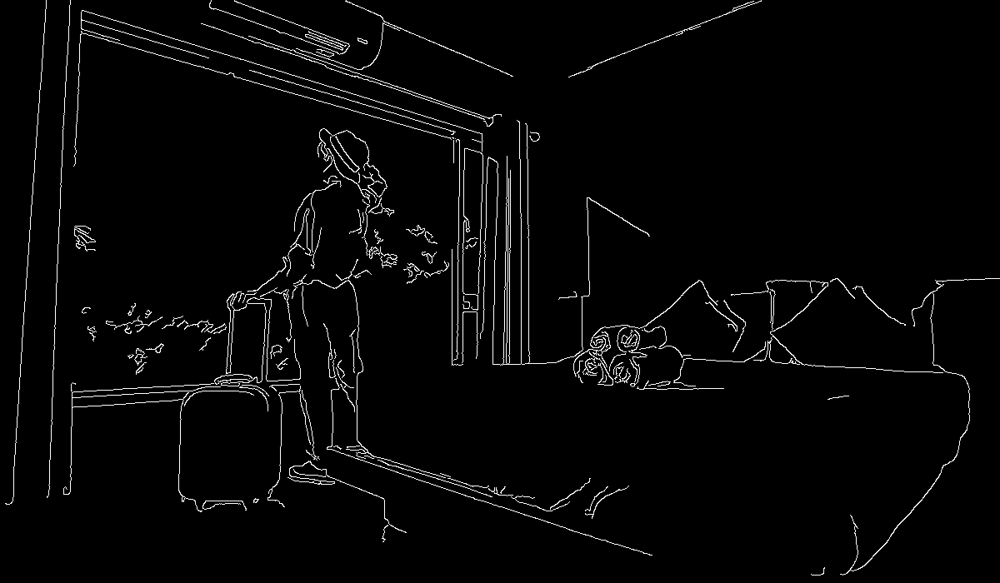

In [11]:
edges = detect_edges_simple(item['input'])
edge_image = Image.fromarray(edges)
edge_image

#### Canny on input without Greyscale

Inside func:  <class 'numpy.ndarray'> (700, 1200)


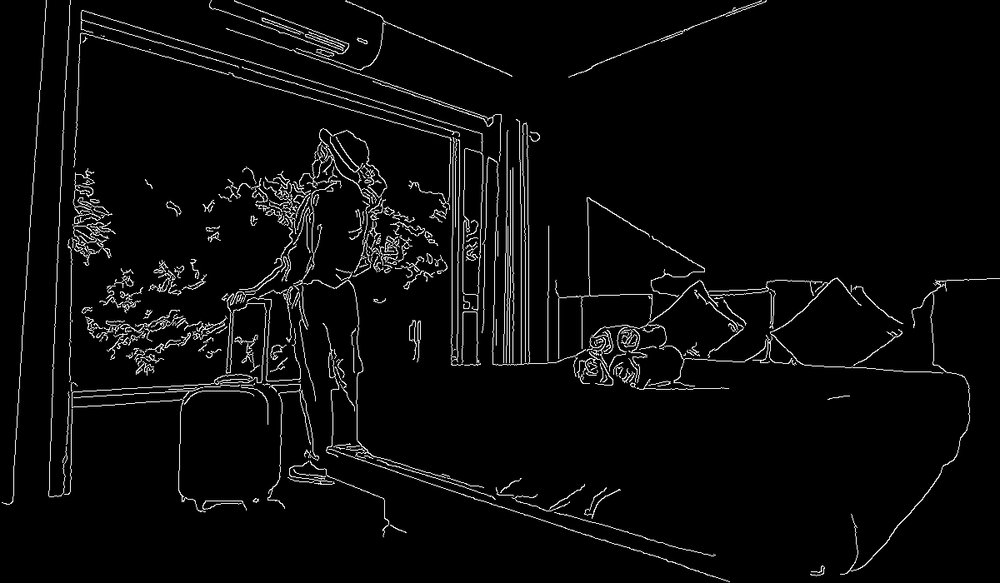

In [12]:
edges = detect_edges_no_greyscale(item['input'])
edge_image = Image.fromarray(edges)
edge_image

#### Canny on Normal Image with GreyScale

Inside func:  <class 'numpy.ndarray'> (700, 1200)


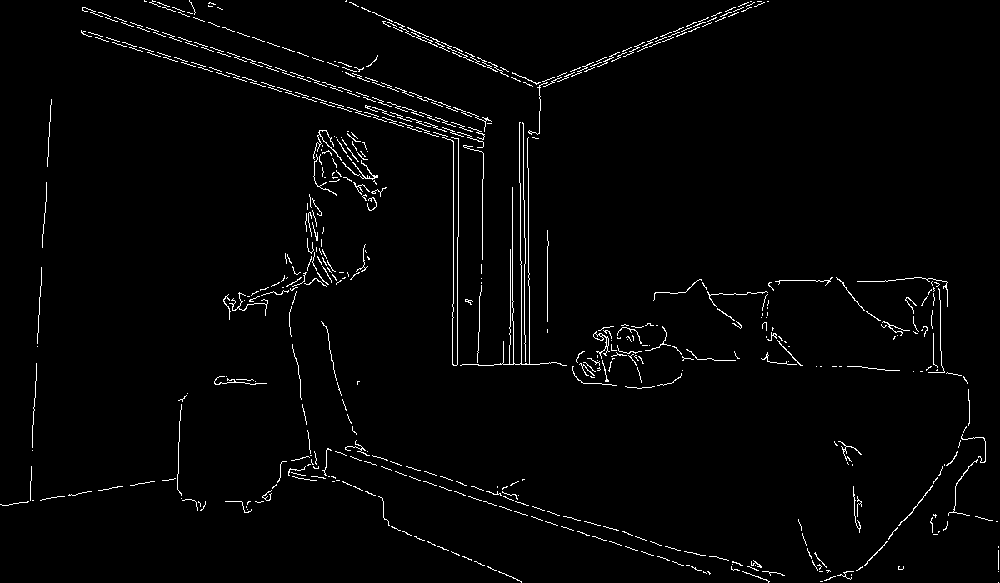

In [13]:
edges = detect_edges_simple(item['nor_img'])
type(edges)
edge_image = Image.fromarray(edges)
edge_image

#### Canny on Normal Image without GreyScale

Inside func:  <class 'numpy.ndarray'> (700, 1200)


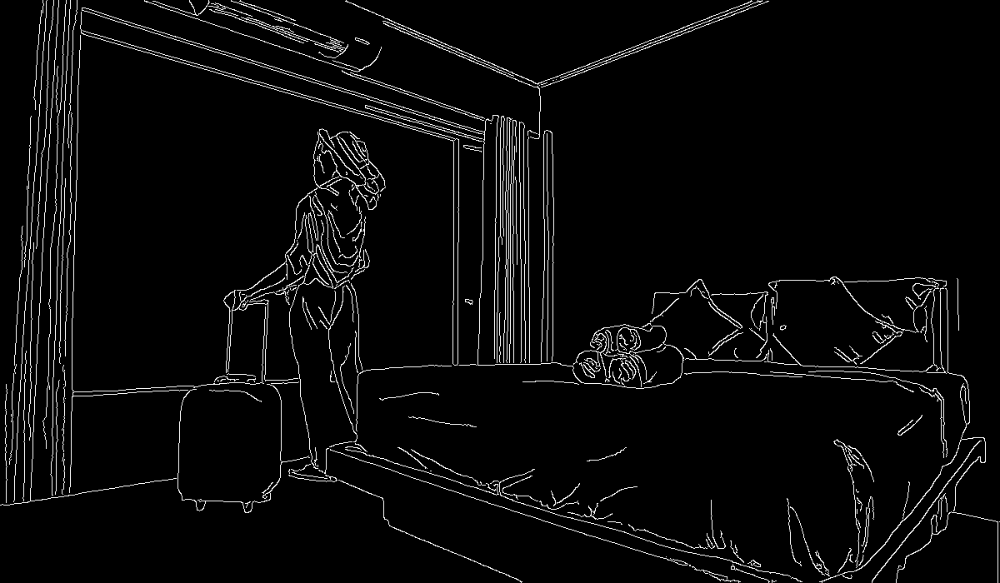

In [14]:
edges = detect_edges_no_greyscale(item['nor_img'])
type(edges)
edge_image = Image.fromarray(edges)
edge_image

### Comparison of Outputs

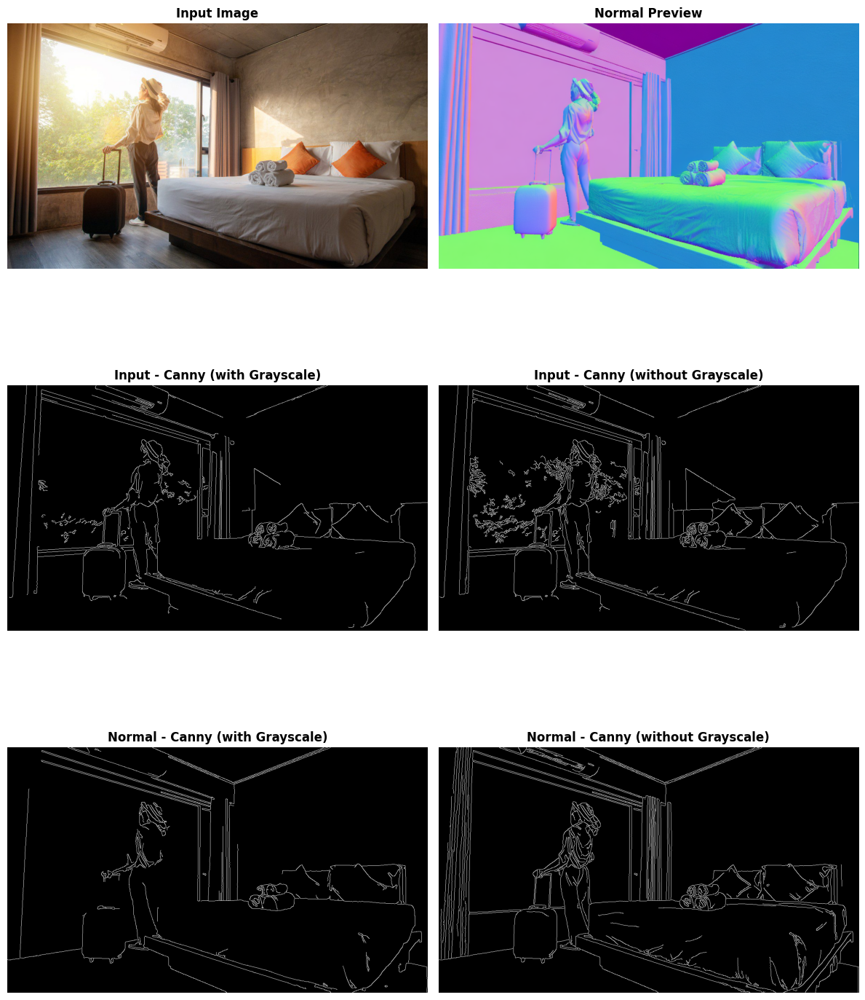

In [15]:
# Testing on Sample Image - Combined Canny Detection Visualization
import cv2

def canny_detect(img_path, use_grayscale=True):
    """Apply Canny edge detection with optional grayscale conversion."""
    img = cv2.imread(str(img_path))
    if use_grayscale:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    return cv2.Canny(blurred, 50, 150)

# Load images
input_img = Image.open(item['input'])
normal_img = Image.open(item['nor_img'])

# Generate Canny edges
input_canny_gray = canny_detect(item['input'], use_grayscale=True)
input_canny_rgb = canny_detect(item['input'], use_grayscale=False)
normal_canny_gray = canny_detect(item['nor_img'], use_grayscale=True)
normal_canny_rgb = canny_detect(item['nor_img'], use_grayscale=False)

# Display in 3x2 grid
fig, axes = plt.subplots(3, 2, figsize=(12, 16))

axes[0, 0].imshow(input_img)
axes[0, 0].set_title('Input Image', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(normal_img)
axes[0, 1].set_title('Normal Preview', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

axes[1, 0].imshow(input_canny_gray, cmap='gray')
axes[1, 0].set_title('Input - Canny (with Grayscale)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(input_canny_rgb, cmap='gray')
axes[1, 1].set_title('Input - Canny (without Grayscale)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

axes[2, 0].imshow(normal_canny_gray, cmap='gray')
axes[2, 0].set_title('Normal - Canny (with Grayscale)', fontsize=12, fontweight='bold')
axes[2, 0].axis('off')

axes[2, 1].imshow(normal_canny_rgb, cmap='gray')
axes[2, 1].set_title('Normal - Canny (without Grayscale)', fontsize=12, fontweight='bold')
axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

Note: Looking at the output, I feel running the Canny on a normal map of the image retains the relevant edges better and more sharply than the input. The Canny may perform even better on the output of the albedo channel.

### Future To-Do: Run this experiment on all images, save these comparison images in a separate folder to see if this is consistently a good choice

# Experiment: Find seeds for wall sampling
Randomly sample pixels and filter them using the SegFormer output to find out if they are good seeds for making the wall pixel mask. 

### Pixel Sampling function

In [16]:
def sample_pixels_by_threshold(image, threshold_array, threshold=0.5, sampling_divisor=500):
    """
    Randomly sample pixels from an image and return those exceeding threshold.
    
    Args:
        image: PIL Image or numpy array (H×W×C or H×W)
        threshold_array: numpy array (H×W) with values to check against threshold
        threshold: threshold value (default: 0.5)
        sampling_divisor: divides total pixels to get sample count (default: 500)
    
    Returns:
        list of tuples: [(y, x), ...] coordinates of pixels exceeding threshold
        number of samples = (H * W) // sampling_divisor
    """
    img = cv2.imread(str(image))
    arr = np.array(img) if not isinstance(img, np.ndarray) else img
    h, w = arr.shape[:2]
    n_samples = (h * w) // sampling_divisor
    
    # # Random sample of pixel coordinates
    # sample_coords = np.random.Generator.integers(0, h * w, n_samples)
    # y_coords = sample_coords // w
    # x_coords = sample_coords - (y_coords * w)

    # Random sample of pixel coordinates
    rng = np.random.default_rng(seed=42)  # Create generator with seed
    sample_coords = rng.integers(0, h * w, n_samples)
    y_coords = sample_coords // w
    x_coords = sample_coords % w  # More idiomatic than subtraction
    
    # Filter by threshold
    mask = threshold_array[y_coords, x_coords] > threshold
    
    return [list(zip(y_coords[mask], x_coords[mask])), n_samples]

In [17]:
# Sample wall pixels from confidence map
wall_pixels, n_samples = sample_pixels_by_threshold(
    image=item['input'],
    threshold_array=np.load(item['wall_npy']),
    threshold=0.9,
    sampling_divisor=2000
)
print(f"Found {len(wall_pixels)} wall pixels from {n_samples} samples")

Found 100 wall pixels from 420 samples


### Pixel Visualisation Function

In [18]:
def visualize_sampled_pixels(image, pixel_coords, spot_size=5):
    """
    Create overlay with white spots at sampled pixel coordinates.
    
    Args:
        image: PIL Image or numpy array
        pixel_coords: list of (y, x) tuples
        spot_size: diameter of white spots in pixels (default: 5)
    
    Returns:
        PIL Image with white spots overlaid
    """
    image = cv2.imread(str(image))
    img = Image.fromarray(np.array(image)) if isinstance(image, np.ndarray) else image.copy()
    overlay = np.array(img)
    radius = spot_size // 2
    
    for y, x in pixel_coords:
        y_min, y_max = max(0, y - radius), min(overlay.shape[0], y + radius + 1)
        x_min, x_max = max(0, x - radius), min(overlay.shape[1], x + radius + 1)
        overlay[y_min:y_max, x_min:x_max] = 255
    
    return Image.fromarray(overlay)

### Run on Sample Image

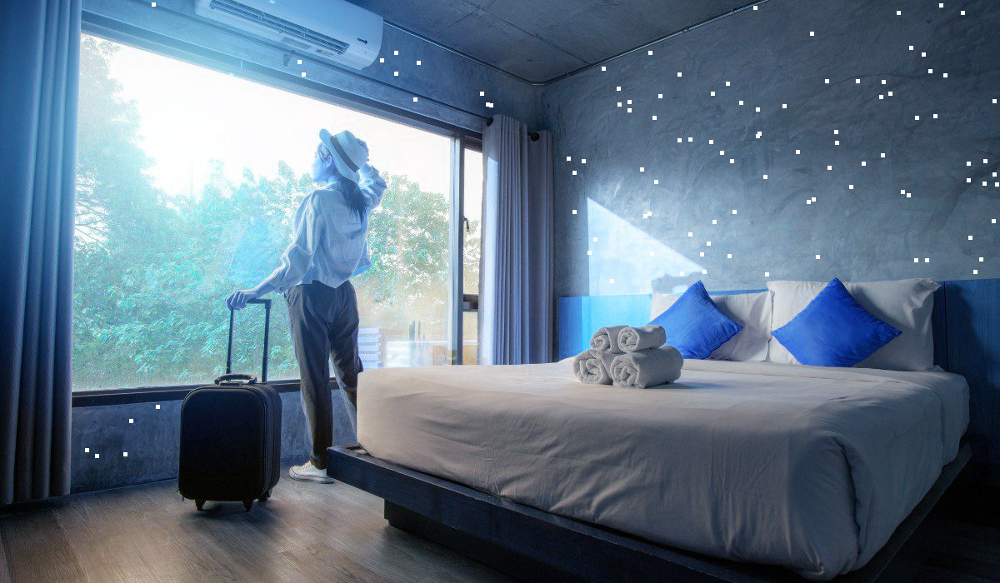

In [19]:
# Visualize
overlay_img = visualize_sampled_pixels(item['input'], wall_pixels, spot_size=5)
overlay_img  # Display in notebook

### Trying to get the expand-and-merge strategy to work for the seeds

In [20]:
# Each seed tries to expand to neighboring pixels and can do so as long as the value of the neighboring pixel
# is close to the seed pixel's value in the normal numpy array AND Crosses the threshold to be classified as 
# a wall. Each seed grows its region iteratively. If two seeds' regions touch, they merge into one if 
# the values are close. 

# If a seed encounter's a pixel that is too different in value, 

## Trying a strategy that starts from the edges from the normal map and building walls from it using the segformer output

In [21]:
type(normal_canny_rgb)

numpy.ndarray

In [22]:
normal_canny_rgb

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ..., 255,   0,   0],
       [  0,   0,   0, ..., 255,   0,   0],
       [  0,   0,   0, ..., 255,   0,   0]],
      shape=(700, 1200), dtype=uint8)

In [23]:
## Checking all possible values in the edge map
np.unique(normal_canny_rgb)

array([  0, 255], dtype=uint8)

In [24]:
def overlay_mask_on_image(rgb_image, mask_array, opacity=0.5, overlay_thickness=1):
    """
    Overlays a binary mask on an RGB image with reduced opacity.
    
    Parameters:
    -----------
    rgb_image : np.ndarray or PIL.Image
        RGB image (H, W, 3)
    mask_array : np.ndarray
        Binary array with values 0 and 255 (H, W)
    opacity : float
        Opacity of the base image (0.0 to 1.0), default 0.5
    overlay_thickness : int
        Thickness of the black overlay lines in pixels, default 1
    
    Returns:
    --------
    PIL.Image
        Combined image with overlay
    """
    # Convert to PIL if Posix Path
    if isinstance(rgb_image, (str, Path)):
        rgb_image = Image.open(str(rgb_image)).convert('RGB')
    # Convert PIL to numpy if needed
    if isinstance(rgb_image, Image.Image):
        rgb_image = np.array(rgb_image)
    
    # Create output image with reduced opacity
    result = (rgb_image * opacity).astype(np.uint8)
    
    # Handle thickness > 1 by dilating the mask
    if overlay_thickness > 1:
        kernel = np.ones((overlay_thickness, overlay_thickness), np.uint8)
        mask_dilated = cv2.dilate(mask_array.astype(np.uint8), kernel, iterations=1)
    else:
        mask_dilated = mask_array.astype(np.uint8)
    
    # Apply black overlay where mask is 255
    result[mask_dilated == 255] = [0, 0, 0]
    
    return Image.fromarray(result)

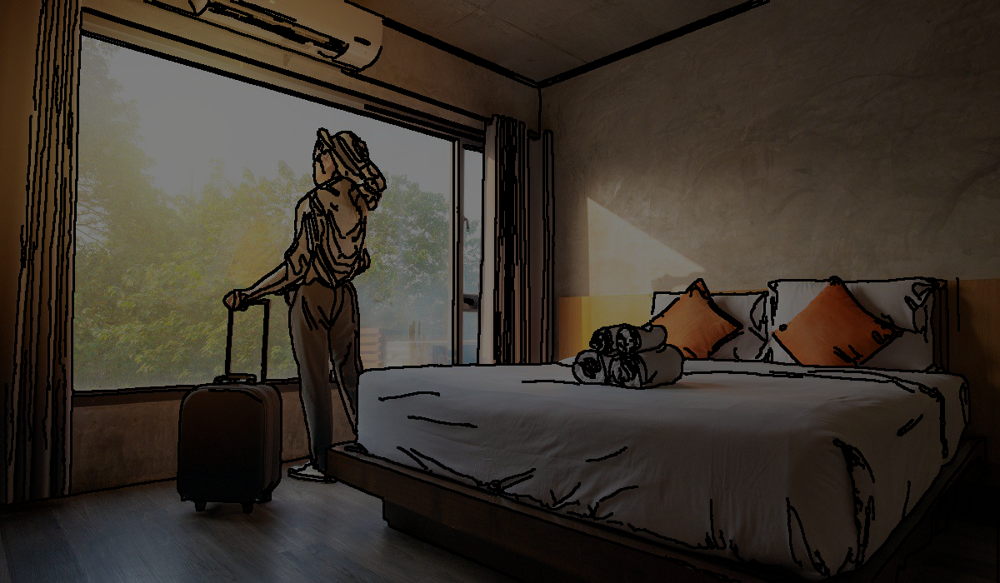

In [25]:
result_img = overlay_mask_on_image(item['input'], 
                                   normal_canny_rgb, 
                                   opacity=0.5, overlay_thickness=3)
result_img

In [26]:
segmentation_mask = np.load(item['wall_npy'])
normals = np.load(item['nor_npy'])

In [27]:
normals

array([[[0.6660156 , 0.6074219 , 0.8955078 ],
        [0.6623535 , 0.5817871 , 0.9313965 ],
        [0.6602783 , 0.56241864, 0.94905597],
        ...,
        [0.15582275, 0.5503743 , 0.8288574 ],
        [0.1586914 , 0.5430908 , 0.81518555],
        [0.17114258, 0.5024414 , 0.75878906]],

       [[0.6391253 , 0.5790974 , 0.91845423],
        [0.6534797 , 0.5695968 , 0.95004046],
        [0.66682166, 0.56209   , 0.9587365 ],
        ...,
        [0.14052513, 0.5415603 , 0.82297146],
        [0.14520141, 0.54452497, 0.82863075],
        [0.15805595, 0.54905134, 0.8233259 ]],

       [[0.6304827 , 0.5702079 , 0.93328685],
        [0.6480922 , 0.5622611 , 0.9531145 ],
        [0.6656076 , 0.5587292 , 0.9559599 ],
        ...,
        [0.13214432, 0.53562766, 0.8137004 ],
        [0.13338274, 0.53797084, 0.82179826],
        [0.13577358, 0.5425223 , 0.8284528 ]],

       ...,

       [[0.5263951 , 0.9964635 , 0.45719168],
        [0.5003444 , 0.99707556, 0.44143152],
        [0.49575835, 0

In [28]:
all_wall_pixels = normals[segmentation_mask > 0.9]
all_wall_pixels.shape

(191626, 3)

In [29]:
np.unique(all_wall_pixels, axis=0)

array([[0.08107689, 0.25256097, 0.6076478 ],
       [0.09180211, 0.23613368, 0.59832066],
       [0.0932344 , 0.26251626, 0.6339303 ],
       ...,
       [0.9029496 , 0.54074556, 0.93841517],
       [0.90545934, 0.5535896 , 0.95010114],
       [0.91414386, 0.5680949 , 0.9407959 ]],
      shape=(191626, 3), dtype=float32)

In [30]:
# Pseudocode
refined_mask = segmentation_mask.copy()

# Get confident wall normals
# wall_normal_mean = compute_mean_normal(normals[segmentation_mask])
wall_normal_mean = np.mean(normals[segmentation_mask > 0.9])
print(wall_normal_mean)

# # Find boundary region
# boundary = get_boundary_pixels(segmentation_mask, width=5)

# # Refine each boundary pixel
# for pixel in boundary:
#     normal_similarity = cosine_similarity(normals[pixel], wall_normal_mean)
    
#     if normal_similarity > threshold:  # e.g., 0.95
#         refined_mask[pixel] = WALL
#     else:
#         refined_mask[pixel] = NOT_WALL

0.5309984


## DBSCAN (Density-Based Spatial Clustering of Applications with Noise) 
DBSCAN is a clustering algorithm that groups together points that are densely packed in space, while marking points in low-density regions as outliers.
How DBSCAN Works
Core Concepts:
- Epsilon (ε): Maximum distance between two points to be considered neighbors
- MinPts: Minimum number of points required to form a dense region (cluster)
- Core points: Points with at least MinPts neighbors within ε distance
- Border points: Points within ε of a core point but with fewer than MinPts neighbors
- Noise points: Points that are neither core nor border points

### DBSCAN for Normal Vectors
When clustering normal vectors (like surface normals from your segmentation), DBSCAN is particularly useful because:
Why Use DBSCAN for Normals?
Automatic cluster detection: Unlike K-means, you don't need to specify the number of walls/planes in advance
Handles noise: Identifies outlier normals that don't belong to any major surface
Arbitrary shapes: Can find clusters of any shape (though normals typically form tight groups)
Density-based: Perfect for normals where you expect tight clusters representing planar surfaces
Distance Metric Matters
For normal vectors, you should use angular distance or cosine distance instead of Euclidean:

In [31]:
## DBSCAN Causing Kernel to Crash

# from sklearn.cluster import DBSCAN
# from sklearn.metrics.pairwise import cosine_similarity
# import numpy as np

# # Your normals from the selected line
# wall_normals = normals[segmentation_mask > 0.9]  # Shape: (N, 3)

# # Option 1: Using cosine distance (1 - cosine similarity)
# # DBSCAN with precomputed distance matrix
# from sklearn.metrics.pairwise import cosine_distances
# distance_matrix = cosine_distances(wall_normals)

# dbscan = DBSCAN(
#     eps=0.1,           # Max angular difference (small = strict)
#     min_samples=1000,    # Min points to form a wall cluster
#     metric='precomputed'
# )
# labels = dbscan.fit_predict(distance_matrix)

In [32]:
# # Option 2: Using angular distance directly
# # Convert to angles (in radians)
# def angular_distance(X):
#     # Returns angle between unit vectors
#     similarity = np.clip(X @ X.T, -1.0, 1.0)
#     return np.arccos(similarity)

# dbscan2 = DBSCAN(
#     eps=0.087,         # ~5 degrees in radians
#     min_samples=50,
#     metric='precomputed'
# )
# labels2 = dbscan2.fit_predict(angular_distance(wall_normals))

In [33]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)

    # Sample every 10th point (191k → 19k)
    sampled_indices = np.arange(0, len(normals), 10)
    wall_normals_sampled = normals[sampled_indices]

    segmentation_mask_sampled = segmentation_mask[sampled_indices]
    # Before clustering, clean the normals
    wall_normals = wall_normals_sampled[segmentation_mask_sampled > 0.9]

    # 1. Remove NaN and Inf
    valid_mask = np.isfinite(wall_normals).all(axis=1)
    wall_normals_clean = wall_normals[valid_mask]

    # 2. Remove zero-length vectors
    norms = np.linalg.norm(wall_normals_clean, axis=1)
    non_zero_mask = norms > 1e-6  # Small threshold to avoid near-zero
    wall_normals_clean = wall_normals_clean[non_zero_mask]

    # 3. Normalize to unit vectors
    wall_normals_clean = wall_normals_clean / np.linalg.norm(wall_normals_clean, axis=1, keepdims=True)

    print(f"Filtered from {len(wall_normals)} to {len(wall_normals_clean)} valid normals")

    # Now cluster
    from sklearn.cluster import OPTICS
    optics = OPTICS(max_eps=0.1, min_samples=50, metric='cosine')
    labels = optics.fit_predict(wall_normals_clean)
    print(f"Found {len(set(labels)) - (1 if -1 in labels else 0)} clusters (excluding noise)")

Filtered from 19381 to 19381 valid normals
Found 2 clusters (excluding noise)


In [34]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    # Flatten the 3D array to work with 1D indices
    W, H = normals.shape[0], normals.shape[1]
    normals_flat = normals.reshape(-1, 3)  # Shape: [W*H, 3]
    segmentation_mask_flat = segmentation_mask.flatten()  # Shape: [W*H]

    # Start with original flat indices
    original_indices = np.arange(0, W*H)

    # Step 1: Downsample
    sampled_indices = np.arange(0, W*H, 10)
    track_indices = original_indices[sampled_indices]
    normals_sampled = normals_flat[sampled_indices]
    segmentation_mask_sampled = segmentation_mask_flat[sampled_indices]

    # Step 2: Apply segmentation mask
    mask_filter = segmentation_mask_sampled > 0.9
    track_indices = track_indices[mask_filter]
    wall_normals = normals_sampled[mask_filter]

    # Step 3: Remove invalid (NaN/Inf)
    valid_mask = np.isfinite(wall_normals).all(axis=1)
    track_indices = track_indices[valid_mask]
    wall_normals_clean = wall_normals[valid_mask]

    # Step 4: Remove zero-length
    norms = np.linalg.norm(wall_normals_clean, axis=1)
    non_zero_mask = norms > 1e-6
    track_indices = track_indices[non_zero_mask]
    wall_normals_clean = wall_normals_clean[non_zero_mask]

    # Step 5: Normalize and cluster
    wall_normals_clean = wall_normals_clean / np.linalg.norm(wall_normals_clean, axis=1, keepdims=True)
    labels = optics.fit_predict(wall_normals_clean)

    

In [35]:
# Step 6: Map back to original 2D array
input_array = np.full((W, H), -1)
result_array = np.full((W, H), -1)
for i, original_idx in enumerate(track_indices):
    row, col = np.unravel_index(original_idx, (W, H))
    result_array[row, col] = labels[i]
    input_array[row, col] = 1

print(f"Found {len(set(labels)) - (1 if -1 in labels else 0)} clusters (excluding noise)")
print("Labelled mask array shape: ", result_array.shape)


Found 3 clusters (excluding noise)
Labelled mask array shape:  (700, 1200)


In [36]:
np.unique(result_array, return_counts=True)

(array([-1,  0,  1,  2]), array([837259,   2638,     52,     51]))

## Interpreting Results: Visualising the output of the clustering algorithm

In [37]:
# def overlay_multiclass_mask_on_image(rgb_image, mask_array, opacity=0.5, overlay_alpha=0.7, 
#                                     overlay_thickness=1, colormap='tab10', 
#                                     treat_zero_as_background=True):
#     """
#     Overlays a multi-class mask on an RGB image with different colors for each class.
    
#     Parameters:
#     -----------
#     rgb_image : np.ndarray, PIL.Image, or Path
#         RGB image (H, W, 3)
#     mask_array : np.ndarray
#         Multi-class mask array (H, W) with integer values representing different classes
#     opacity : float
#         Opacity of the base image (0.0 to 1.0), default 0.5
#     overlay_alpha : float
#         Alpha blending for colored overlays (0.0 to 1.0), default 0.7
#     overlay_thickness : int
#         Thickness of overlay regions in pixels (via dilation), default 1
#     colormap : str
#         Matplotlib colormap name ('tab10', 'Set3', 'hsv', etc.), default 'tab10'
#     treat_zero_as_background : bool
#         If True, value 0 is treated as background and not colored, default True
    
#     Returns:
#     --------
#     dict containing:
#         - 'image': PIL.Image - Combined image with colored overlay
#         - 'color_map': dict - Mapping of class values to RGB colors
#         - 'num_classes': int - Number of unique classes found
#     """
#     import matplotlib.pyplot as plt
#     import matplotlib.cm as cm
    
#     # Convert to PIL if Path
#     if isinstance(rgb_image, (str, Path)):
#         rgb_image = Image.open(str(rgb_image)).convert('RGB')
#     # Convert PIL to numpy if needed
#     if isinstance(rgb_image, Image.Image):
#         rgb_image = np.array(rgb_image)
    
#     # Find unique values in mask
#     unique_values = np.unique(mask_array)
    
#     # Filter out background if requested
#     if treat_zero_as_background and 0 in unique_values:
#         unique_values = unique_values[unique_values != 0]
    
#     num_classes = len(unique_values)
#     print(f"Found {num_classes} unique classes: {unique_values}")
    
#     # Generate colors using matplotlib colormap
#     cmap = cm.get_cmap(colormap)
#     color_map = {}
    
#     for idx, value in enumerate(unique_values):
#         # Get color from colormap (normalized index)
#         color_normalized = cmap(idx / max(num_classes - 1, 1))[:3]  # RGB only, no alpha
#         color_rgb = tuple(int(c * 255) for c in color_normalized)
#         color_map[value] = color_rgb
#         print(f"Class {value}: RGB{color_rgb}")
    
#     # Create output image with reduced opacity
#     result = (rgb_image * opacity).astype(np.uint8)
    
#     # Apply each class color as an overlay
#     for value, color in color_map.items():
#         # Create binary mask for this class
#         class_mask = (mask_array == value).astype(np.uint8) * 255
        
#         # Handle thickness > 1 by dilating the mask
#         if overlay_thickness > 1:
#             kernel = np.ones((overlay_thickness, overlay_thickness), np.uint8)
#             class_mask = cv2.dilate(class_mask, kernel, iterations=1)
        
#         # Create colored overlay for this class
#         class_overlay = np.zeros_like(rgb_image)
#         class_overlay[class_mask == 255] = color
        
#         # Blend the class overlay onto result using overlay_alpha
#         mask_indices = class_mask == 255
#         result[mask_indices] = (
#             (1 - overlay_alpha) * result[mask_indices] + 
#             overlay_alpha * class_overlay[mask_indices]
#         ).astype(np.uint8)
    
#     return {
#         'image': Image.fromarray(result),
#         'color_map': color_map,
#         'num_classes': num_classes
#     }

In [38]:
def overlay_multiclass_mask_on_image(rgb_image, mask_array, background_ind, opacity=0.5, overlay_alpha=0.7, 
                                     overlay_thickness=1, colormap='tab10'):
    """
    Overlays a multi-class mask on an RGB image with different colors for each class.
    
    Parameters:
    -----------
    rgb_image : np.ndarray, PIL.Image, or Path
        RGB image (H, W, 3)
    mask_array : np.ndarray
        Multi-class mask array (H, W) with integer values representing different classes
    background_ind : int
        Value in mask_array to treat as background (not colored)
    opacity : float
        Opacity of the base image (0.0 to 1.0), default 0.5
    overlay_alpha : float
        Alpha blending for colored overlays (0.0 to 1.0), default 0.7
    overlay_thickness : int
        Thickness of overlay regions in pixels (via dilation), default 1
    colormap : str
        Matplotlib colormap name ('tab10', 'Set3', 'hsv', etc.), default 'tab10'
    
    Returns:
    --------
    dict containing:
        - 'image': PIL.Image - Combined image with colored overlay
        - 'color_map': dict - Mapping of class values to RGB colors
        - 'num_classes': int - Number of unique classes found
    """
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    
    # Convert to PIL if Path
    if isinstance(rgb_image, (str, Path)):
        rgb_image = Image.open(str(rgb_image)).convert('RGB')
    # Convert PIL to numpy if needed
    if isinstance(rgb_image, Image.Image):
        rgb_image = np.array(rgb_image)
    
    # Find unique values in mask
    unique_values = np.unique(mask_array)
    
    # Filter out background if requested
    if background_ind in unique_values:
        unique_values = unique_values[unique_values != background_ind]
    
    num_classes = len(unique_values)
    print(f"Found {num_classes} unique classes: {unique_values}")
    
    # Generate colors using matplotlib colormap
    cmap = cm.get_cmap(colormap)
    color_map = {}
    
    for idx, value in enumerate(unique_values):
        # Get color from colormap (normalized index)
        color_normalized = cmap(idx / max(num_classes - 1, 1))[:3]  # RGB only, no alpha
        color_rgb = tuple(int(c * 255) for c in color_normalized)
        color_map[value] = color_rgb
        print(f"Class {value}: RGB{color_rgb}")
    
    # Create output image with reduced opacity
    result = (rgb_image * opacity).astype(np.uint8)
    
    # Apply each class color as an overlay
    for value, color in color_map.items():
        # Create binary mask for this class
        class_mask = (mask_array == value).astype(np.uint8) * 255
        
        # Handle thickness > 1 by dilating the mask
        if overlay_thickness > 1:
            kernel = np.ones((overlay_thickness, overlay_thickness), np.uint8)
            class_mask = cv2.dilate(class_mask, kernel, iterations=1)
        
        # Create colored overlay for this class
        class_overlay = np.zeros_like(rgb_image)
        class_overlay[class_mask == 255] = color
        
        # Blend the class overlay onto result using overlay_alpha
        mask_indices = class_mask == 255
        result[mask_indices] = (
            (1 - overlay_alpha) * result[mask_indices] + 
            overlay_alpha * class_overlay[mask_indices]
        ).astype(np.uint8)
    
    return {
        'image': Image.fromarray(result),
        'color_map': color_map,
        'num_classes': num_classes
    }

Found 3 unique classes: [0 1 2]
Class 0: RGB(31, 119, 180)
Class 1: RGB(140, 86, 75)
Class 2: RGB(23, 190, 207)


/var/folders/wj/47jmz7gj0gj8fjfh01t9pkkr0000gp/T/ipykernel_22355/3396215299.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(colormap)


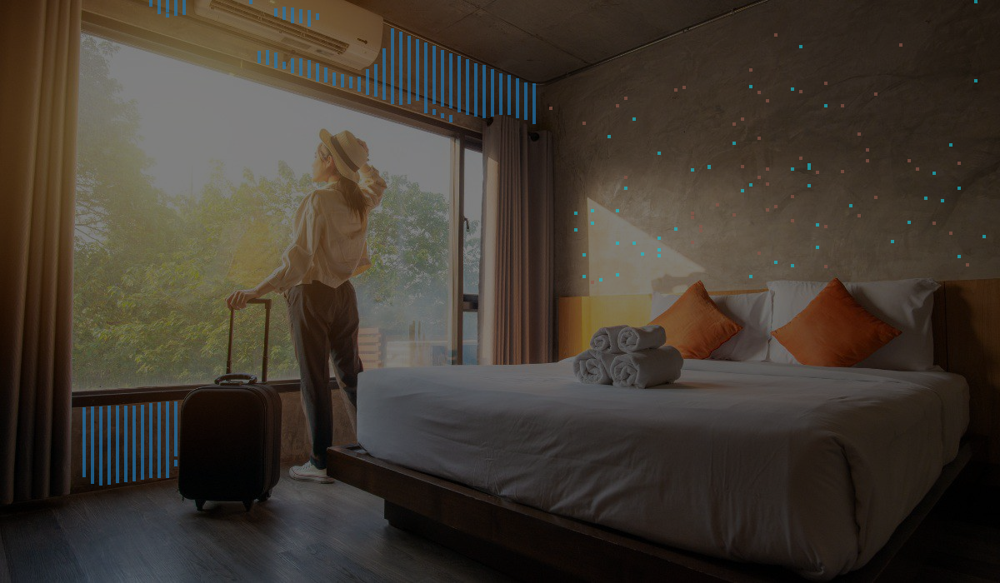

In [39]:
output= overlay_multiclass_mask_on_image(item['input'], result_array, opacity=0.5, overlay_thickness=4, background_ind=-1)
output['image']

## Function: Calculate Mean Normal Vectors per Class

Perfect! I can see from the notebook that you have:
Normal vectors stored in normals (shape: H×W×3, values in [0,1] range)
Multi-class mask arrays from clustering (like result_array with values -1, 0, 1, 2)
You're already computing mean normals in cell 64 (from the earlier DBSCAN experiment)
Now I'll create a comprehensive function that calculates the mean normal vector for each class in the mask. Here's the complete function:


In [40]:
def calculate_class_mean_normals(normal_array, mask_array, background_value=-1, 
                                 normalize_output=True, min_pixels=10):
    """
    Calculate the mean normal vector for each class in a multi-class mask.
    
    This function:
    1. Identifies all unique classes in the mask (excluding background)
    2. For each class, extracts all corresponding normal vectors
    3. Computes the mean normal vector for each class
    4. Optionally normalizes the mean vectors to unit length
    5. Provides statistics (pixel count, variance) for each class
    
    Parameters:
    -----------
    normal_array : np.ndarray
        Normal map array (H, W, 3) with values typically in [0, 1] or [-1, 1]
    mask_array : np.ndarray
        Multi-class mask array (H, W) with integer class labels
    background_value : int or None
        Value to treat as background (will be excluded), default -1
        Set to None to include all values
    normalize_output : bool
        If True, normalize mean normals to unit vectors, default True
    min_pixels : int
        Minimum number of pixels required for a class to be included, default 10
        Classes with fewer pixels will be excluded from results
    
    Returns:
    --------
    dict containing:
        - 'mean_normals': dict - {class_id: mean_normal_vector (3,)}
        - 'class_stats': dict - {class_id: {'count': int, 'std': float, 'normalized': bool}}
        - 'num_classes': int - Number of valid classes found
        - 'total_pixels_analyzed': int - Total pixels across all classes
    
    Example:
    --------
    >>> result = calculate_class_mean_normals(normals, result_array, background_value=-1)
    >>> print(f"Found {result['num_classes']} classes")
    >>> for class_id, mean_normal in result['mean_normals'].items():
    >>>     print(f"Class {class_id}: normal = {mean_normal}, pixels = {result['class_stats'][class_id]['count']}")
    """
    
    # Find unique classes
    unique_classes = np.unique(mask_array)
    
    # Filter out background
    if background_value is not None and background_value in unique_classes:
        unique_classes = unique_classes[unique_classes != background_value]
    
    mean_normals = {}
    class_stats = {}
    total_pixels = 0
    
    print(f"Processing {len(unique_classes)} classes (excluding background={background_value})...")
    print("-" * 70)
    
    for class_id in unique_classes:
        # Create binary mask for this class
        class_mask = mask_array == class_id
        
        # Extract normals for this class
        class_normals = normal_array[class_mask]  # Shape: (N, 3)
        n_pixels = len(class_normals)
        
        # Skip if too few pixels
        if n_pixels < min_pixels:
            print(f"Class {class_id:3d}: SKIPPED (only {n_pixels} pixels, min={min_pixels})")
            continue
        
        # Calculate mean normal
        mean_normal = class_normals.mean(axis=0)  # Shape: (3,)
        
        # Calculate standard deviation (measure of normal consistency)
        std_dev = class_normals.std(axis=0).mean()  # Average std across x,y,z
        
        # Normalize to unit vector if requested
        if normalize_output:
            norm = np.linalg.norm(mean_normal)
            if norm > 1e-6:  # Avoid division by zero
                mean_normal = mean_normal / norm
            else:
                print(f"Class {class_id:3d}: WARNING - near-zero mean normal, skipping normalization")
        
        # Store results
        mean_normals[class_id] = mean_normal
        class_stats[class_id] = {
            'count': n_pixels,
            'std': float(std_dev),
            'normalized': normalize_output,
            'mean_magnitude': float(np.linalg.norm(mean_normal))
        }
        total_pixels += n_pixels
        
        # Print summary
        print(f"Class {class_id:3d}: mean_normal = [{mean_normal[0]:6.3f}, {mean_normal[1]:6.3f}, {mean_normal[2]:6.3f}] "
              f"| pixels = {n_pixels:6d} | std = {std_dev:.4f}")
    
    print("-" * 70)
    print(f"Total: {len(mean_normals)} valid classes, {total_pixels} pixels analyzed")
    
    return {
        'mean_normals': mean_normals,
        'class_stats': class_stats,
        'num_classes': len(mean_normals),
        'total_pixels_analyzed': total_pixels
    }

## Visualization Helper Function
Here's an additional function to visualize the mean normals as arrows on the image:

In [41]:
def visualize_mean_normals_on_image(rgb_image, mask_array, mean_normals_dict, 
                                    background_value=-1, arrow_scale=50, 
                                    arrow_thickness=2, opacity=0.7):
    """
    Visualize mean normal vectors as arrows overlaid on the original image.
    
    Parameters:
    -----------
    rgb_image : np.ndarray, PIL.Image, or Path
        RGB image (H, W, 3)
    mask_array : np.ndarray
        Multi-class mask array (H, W)
    mean_normals_dict : dict
        Dictionary mapping class_id to mean_normal_vector (from calculate_class_mean_normals)
    background_value : int
        Background value in mask, default -1
    arrow_scale : float
        Scale factor for arrow length, default 50
    arrow_thickness : int
        Thickness of arrow lines, default 2
    opacity : float
        Base image opacity, default 0.7
    
    Returns:
    --------
    PIL.Image - Image with arrows showing mean normals for each class
    """
    # Convert to PIL if Path
    if isinstance(rgb_image, (str, Path)):
        rgb_image = Image.open(str(rgb_image)).convert('RGB')
    if isinstance(rgb_image, Image.Image):
        rgb_image = np.array(rgb_image)
    
    # Create output image
    result = (rgb_image * opacity).astype(np.uint8).copy()
    
    # For each class, draw an arrow at the centroid
    for class_id, mean_normal in mean_normals_dict.items():
        # Find centroid of this class
        class_mask = mask_array == class_id
        y_coords, x_coords = np.where(class_mask)
        
        if len(y_coords) == 0:
            continue
        
        # Calculate centroid
        centroid_y = int(y_coords.mean())
        centroid_x = int(x_coords.mean())
        
        # Convert normal to arrow direction
        # Normal is in (x, y, z) format from [0,1] range
        # For 2D visualization, we'll use (x, y) components
        # Convert from [0,1] to [-1,1] for proper direction
        normal_2d = (mean_normal[:2] * 2 - 1) * arrow_scale
        
        end_x = int(centroid_x + normal_2d[0])
        end_y = int(centroid_y - normal_2d[1])  # Negative because image y is inverted
        
        # Choose arrow color based on class_id
        arrow_color = (255, 0, 0)  # Red arrows
        
        # Draw arrow
        cv2.arrowedLine(result, 
                       (centroid_x, centroid_y), 
                       (end_x, end_y),
                       arrow_color, 
                       thickness=arrow_thickness,
                       tipLength=0.3)
        
        # Add class label
        cv2.putText(result, 
                   f"C{class_id}", 
                   (centroid_x + 5, centroid_y - 5),
                   cv2.FONT_HERSHEY_SIMPLEX, 
                   0.6, 
                   (255, 255, 255), 
                   2)
    
    return Image.fromarray(result)

## Usage Examples

In [42]:
# Example 1: Calculate mean normals from your clustering results
result = calculate_class_mean_normals(
    normal_array=normals,
    mask_array=result_array,
    background_value=-1,
    normalize_output=True,
    min_pixels=10
)

# Print results
print(f"\nFound {result['num_classes']} wall planes")
for class_id, mean_normal in result['mean_normals'].items():
    stats = result['class_stats'][class_id]
    print(f"Wall {class_id}:")
    print(f"  Mean normal: {mean_normal}")
    print(f"  Pixels: {stats['count']}")
    print(f"  Std dev: {stats['std']:.4f}")
    print(f"  Magnitude: {stats['mean_magnitude']:.4f}")
# Example 2: Visualize with arrows
arrow_viz = visualize_mean_normals_on_image(
    rgb_image=item['input'],
    mask_array=result_array,
    mean_normals_dict=result['mean_normals'],
    background_value=-1,
    arrow_scale=100,
    arrow_thickness=3
)
arrow_viz
# Example 3: Compare wall orientations
result = calculate_class_mean_normals(normals, result_array, background_value=-1)

# Calculate angle between two walls
def angle_between_normals(n1, n2):
    """Calculate angle in degrees between two normal vectors."""
    cos_angle = np.clip(np.dot(n1, n2), -1.0, 1.0)
    angle_rad = np.arccos(cos_angle)
    return np.degrees(angle_rad)

if len(result['mean_normals']) >= 2:
    classes = list(result['mean_normals'].keys())
    n1 = result['mean_normals'][classes[0]]
    n2 = result['mean_normals'][classes[1]]
    angle = angle_between_normals(n1, n2)
    print(f"Angle between wall {classes[0]} and wall {classes[1]}: {angle:.1f}°")


Processing 3 classes (excluding background=-1)...
----------------------------------------------------------------------
Class   0: mean_normal = [ 0.629,  0.408,  0.662] | pixels =   2638 | std = 0.0354
Class   1: mean_normal = [ 0.147,  0.543,  0.827] | pixels =     52 | std = 0.0026
Class   2: mean_normal = [ 0.143,  0.543,  0.828] | pixels =     51 | std = 0.0033
----------------------------------------------------------------------
Total: 3 valid classes, 2741 pixels analyzed

Found 3 wall planes
Wall 0:
  Mean normal: [0.6285583 0.4081861 0.6620412]
  Pixels: 2638
  Std dev: 0.0354
  Magnitude: 1.0000
Wall 1:
  Mean normal: [0.1466597  0.54260916 0.82708293]
  Pixels: 52
  Std dev: 0.0026
  Magnitude: 1.0000
Wall 2:
  Mean normal: [0.14288093 0.5428046  0.827616  ]
  Pixels: 51
  Std dev: 0.0033
  Magnitude: 1.0000
Processing 3 classes (excluding background=-1)...
----------------------------------------------------------------------
Class   0: mean_normal = [ 0.629,  0.408,  0.6

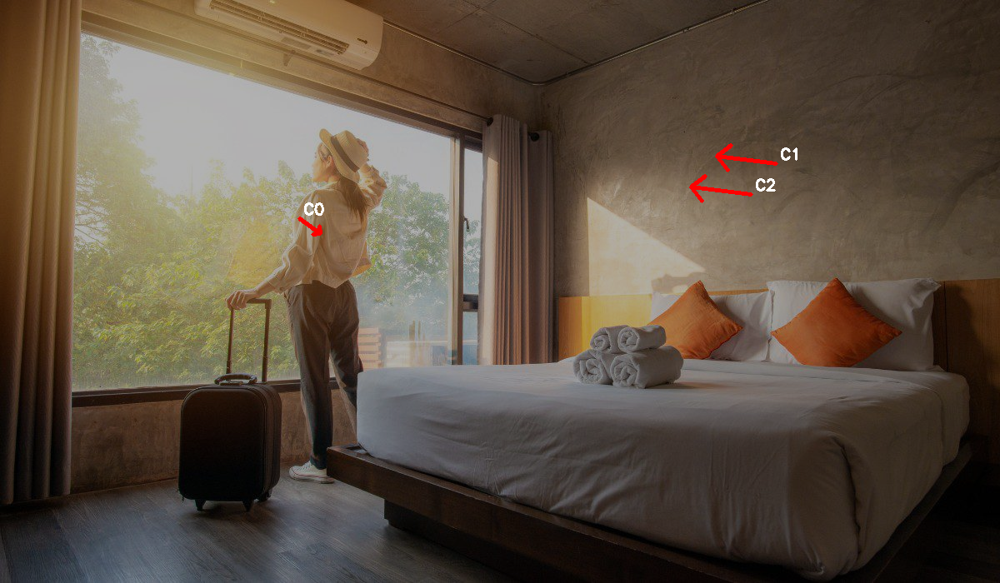

In [43]:
arrow_viz

## Something wasn't working correctly in the clustering algorithm. 
Fix: Visualise the cosine angle between normal vectors in the image to see if the cosine computation isn't working as expected

In [44]:
def compute_consecutive_cosine_angles(normal_array):
    """
    Compute cosine of the angle between horizontally consecutive normal vectors.
    
    For each position (i, j), computes the cosine of the angle between normal_array[i, j] 
    and normal_array[i, j+1], storing the result at output[i, j].
    For the last column (no element to the right), the value is set to 0.
    
    Parameters:
    -----------
    normal_array : np.ndarray
        Array of normal vectors, shape (W, H, 3)
        Each element is a 3D vector [x, y, z] in float format
    
    Returns:
    --------
    np.ndarray
        Array of cosine values, shape (W, H)
        output[i, j] = cosine of angle between normal_array[i, j] and normal_array[i, j+1]
        output[i, H-1] = 0 (last column, no next element)
        
        Cosine values range from -1 to 1:
        - 1.0: vectors point in same direction (0° angle)
        - 0.0: vectors are perpendicular (90° angle)
        - -1.0: vectors point in opposite directions (180° angle)
    
    Example:
    --------
    >>> normals = np.random.rand(700, 1200, 3)  # W=700, H=1200
    >>> cosines = compute_consecutive_cosine_angles(normals)
    >>> print(cosines.shape)
    (700, 1200)
    >>> print(cosines[:, -1])  # Last column should all be 0
    """
    
    # Input validation
    if not isinstance(normal_array, np.ndarray):
        raise TypeError("Input must be a numpy array")
    
    if len(normal_array.shape) != 3 or normal_array.shape[2] != 3:
        raise ValueError(f"Input must have shape (W, H, 3), got {normal_array.shape}")
    
    W, H, _ = normal_array.shape
    
    # Initialize output array with zeros
    cosine_output = np.zeros((W, H), dtype=np.float32)
    
    # Get vectors and their neighbors (all except last column)
    v1 = normal_array[:, :-1, :]  # shape: (W, H-1, 3) - current vectors
    v2 = normal_array[:, 1:, :]   # shape: (W, H-1, 3) - next vectors
    
    # Compute dot products (element-wise multiply then sum across axis 2)
    dot_products = np.sum(v1 * v2, axis=2)  # shape: (W, H-1)
    
    # Compute magnitudes
    v1_magnitudes = np.linalg.norm(v1, axis=2)  # shape: (W, H-1)
    v2_magnitudes = np.linalg.norm(v2, axis=2)  # shape: (W, H-1)
    
    # Compute cosines: cos(θ) = (v1 · v2) / (||v1|| × ||v2||)
    # Add small epsilon to avoid division by zero
    epsilon = 1e-8
    cosines = dot_products / (v1_magnitudes * v2_magnitudes + epsilon)
    
    # Clip to [-1, 1] to handle numerical precision issues
    cosines = np.clip(cosines, -1.0, 1.0)
    
    # Fill output array (all except last column)
    cosine_output[:, :-1] = cosines
    # Last column remains 0 (already initialized)
    
    return cosine_output


print("Function created successfully!")
print("Usage: cosines = compute_consecutive_cosine_angles(normal_array)")
print("  Input shape: (W, H, 3)")
print("  Output shape: (W, H)")
print("Last column will be all zeros. ")

Function created successfully!
Usage: cosines = compute_consecutive_cosine_angles(normal_array)
  Input shape: (W, H, 3)
  Output shape: (W, H)
Last column will be all zeros. 


In [45]:
cosines = compute_consecutive_cosine_angles(normals)

In [46]:
cosines[0]

array([0.999442  , 0.99979347, 0.9999526 , ..., 0.99998504, 0.9996768 ,
       0.        ], shape=(1200,), dtype=float32)

Found 4 unique classes: [0 1 2 3]
Class 0: RGB(0, 104, 55)
Class 1: RGB(183, 224, 117)
Class 2: RGB(253, 190, 111)
Class 3: RGB(165, 0, 38)


/var/folders/wj/47jmz7gj0gj8fjfh01t9pkkr0000gp/T/ipykernel_22355/3396215299.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(colormap)


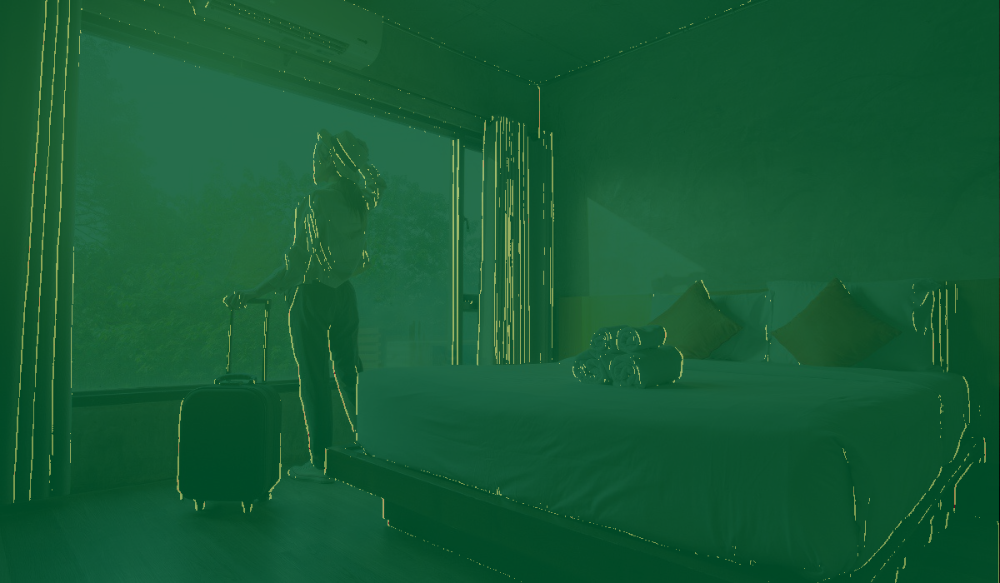

In [47]:
binned_cosines = np.zeros_like(cosines, dtype=int)
binned_cosines[cosines >= 0.99] = 0
binned_cosines[(cosines >= 0.95) & (cosines < 0.99)] = 1
binned_cosines[(cosines >= 0.9) & (cosines < 0.95)] = 2
binned_cosines[cosines < 0.9] = 3
binned_cosines[cosines == 0] = -1  # Last column (background)

# Visualize using your existing function from cell 66
result = overlay_multiclass_mask_on_image(
    rgb_image=item['input'],
    mask_array=binned_cosines,
    background_ind=-1,
    opacity=0.5,
    overlay_alpha=0.7,
    overlay_thickness=1,
    colormap='RdYlGn_r'  # Red = dissimilar, Green = similar
)
result['image']

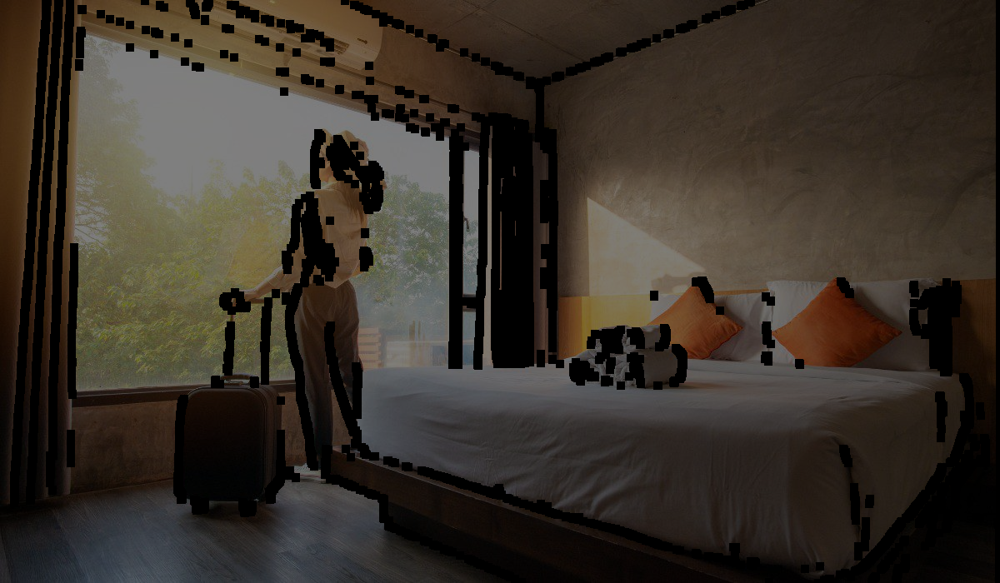

In [52]:
# Threshold: show pixels where normals differ significantly
# Low cosine = large angle difference
threshold = 0.99  # Normals differing by ~18° or more
discontinuity_mask = (cosines < threshold).astype(np.uint8) * 255

# Visualize using your existing function from cell 50
result = overlay_mask_on_image(
    rgb_image=item['input'], 
    mask_array=discontinuity_mask,
    opacity=0.5, 
    overlay_thickness=10
)
result

# Trying a new approach for clustering